In [100]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [101]:
data = pd.read_csv("../../labs-dataset/amz_uk_price_prediction_dataset.csv")

In [102]:
df = data.copy()
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [103]:
print(df.shape)
print(df.info())

(2443651, 9)
<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB
None


In [104]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.35,816056.17,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.15,2.19,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.63,5944.12,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.24,345.61,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,25.90,240.48,0.0,0.00,0.00,0.00,50000.0


Part 1: Analyzing Best-Seller Trends Across Product Categories

In [105]:
# 1. Crosstab Analysis

freq_cat_best = pd.crosstab(df['category'], df['isBestSeller']).sort_values(by=True, ascending=False)
display(freq_cat_best)

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Downhill Ski Boots,1284,0
Digital Frames,774,0
Motorbike Chassis,107,0


In [106]:
## proportion of best sellers for each category
## then sort categories based on proportion in Ascedning=False

proportion_tbl = freq_cat_best[True] / freq_cat_best.sum(axis=1)
proportion_tbl = proportion_tbl.sort_values(ascending=False)
proportion_tbl.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
dtype: float64

Here we display the top 10 bestseller categories.

In [107]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

In [108]:
# 2. Statistics Test

## Chi-Squared Test
_, chi2_p_value, _, _ = chi2_contingency(freq_cat_best)

if chi2_p_value < 0.05:
    print(f"P-value is {chi2_p_value} and we have a correlation between the features.")
elif chi2_p_value >= 0.05:
    print(f"P-value is {chi2_p_value} and there is not enough evidence to conclude a strong correlation between the features.")

P-value is 0.0 and we have a correlation between the features.


In [109]:
## Cramer's V Test

cramer_v = association(freq_cat_best, method='cramer')

if 0 < cramer_v < 0.1:
    print(f"Cramer V is: {cramer_v} = Very weak correlation")
elif 0.1 < cramer_v < 0.2:
    print(f"Cramer V is: {cramer_v} = Weak correlation")
elif 0.2 < cramer_v < 0.3:
    print(f"Cramer V is: {cramer_v} = Moderate correlation")
elif 0.3 < cramer_v < 0.5:
    print(f"Cramer V is: {cramer_v} = Strong correlation")
elif 0.5 < cramer_v:
    print(f"Cramer V is: {cramer_v} = Very strong correlation")


Cramer V is: 0.12228294397605641 = Weak correlation


<Axes: xlabel='category'>

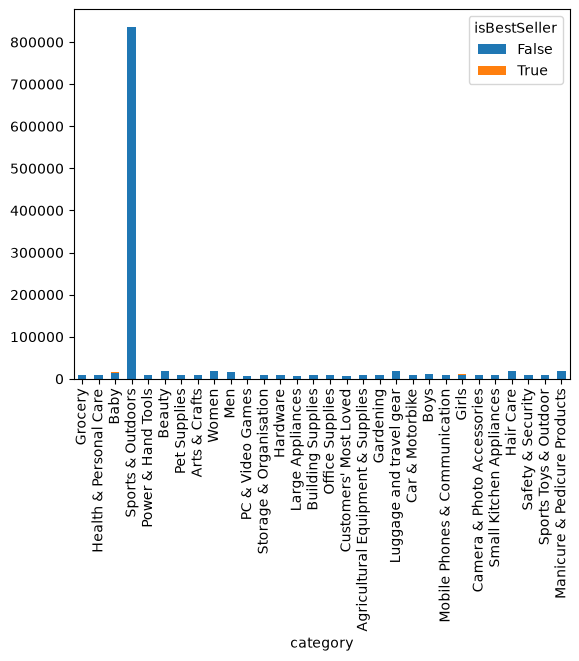

In [110]:
# 3. Visualizations

# Selecting only the top 30 categories for the visualization
top30 = freq_cat_best.head(30)
top30.plot(kind='bar', stacked=True)

Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [111]:
# 0. Remove Outliers in product prices
## IQR = Q3 - Q1
# lower_bound = Q1 - 1.5 * IQR 
# upper_bound Q3 + 1.5 * IQR

# Calculate the Quartiles & Interquartile range:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR 
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]

df_clean = df[(df['price']>= lower_bound) & (df['price']<= upper_bound)]



/var/folders/zn/wkkkj_w57xl5nb23_t676b5w0000gn/T/ipykernel_3290/2626356879.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=top20_df, x='category', y='price', palette='coolwarm')


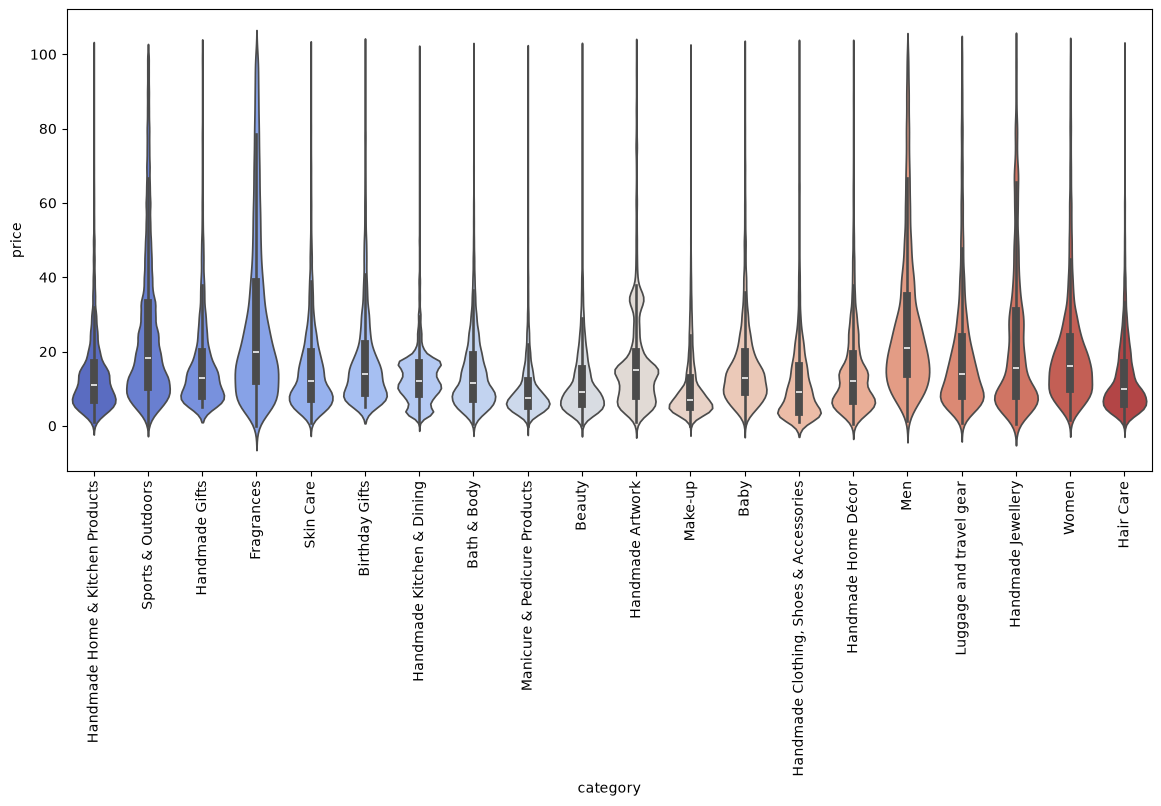

In [136]:
# 1. Violin PLots

top20 = df_clean['category'].value_counts().head(20)
top20_df = df_clean[df_clean['category'].isin(top20.index)]

plt.figure(figsize=(14,6))
sns.violinplot(data=top20_df, x='category', y='price', palette='coolwarm')
plt.xticks(rotation=90)
plt.show()

In [113]:
median_price_by_category = df_clean.groupby('category')['price'].median().sort_values(ascending=False)

print(f"Product categories with the highest median price: {median_price_by_category.head(5)}")

Product categories with the highest median price: category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64


/var/folders/zn/wkkkj_w57xl5nb23_t676b5w0000gn/T/ipykernel_3290/4064746246.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10_df, x='category', y='price', palette='coolwarm')


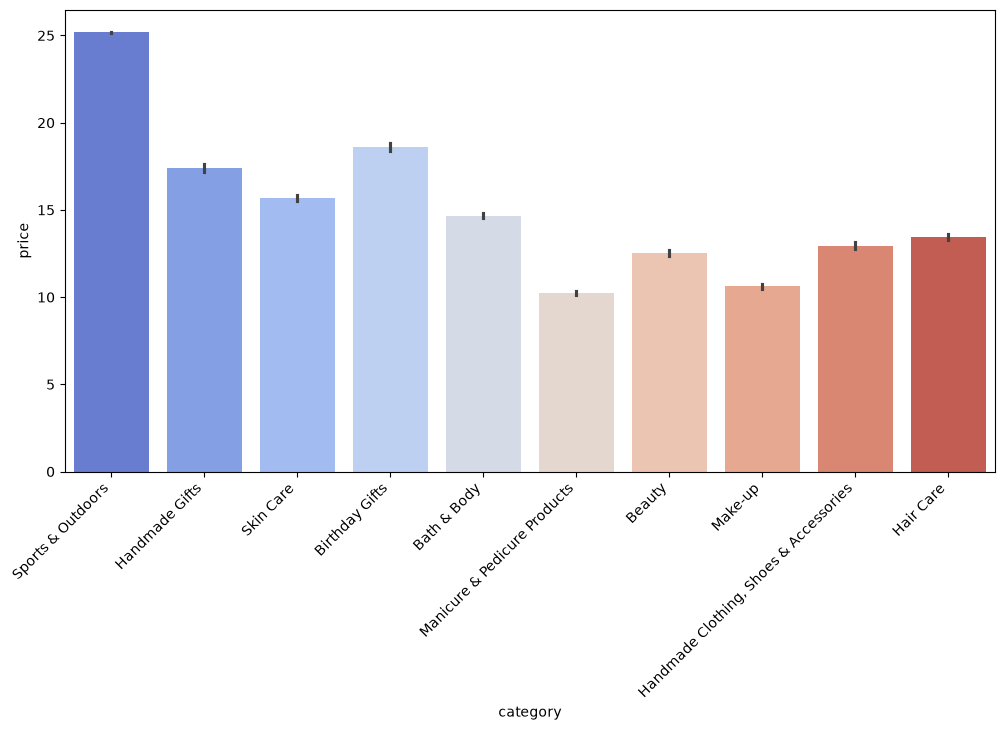

In [ ]:
# 2. Bar Charts

top10 = df_clean['category'].value_counts().head(10)
top10_df = df_clean[df_clean['category'].isin(top10.index)]


plt.figure(figsize=(12,6))
sns.barplot(data=top10_df, x='category', y='price', palette='coolwarm')
plt.xticks(rotation=45, ha='right')
plt.show()

In [132]:
avg_price_top10 = df_clean.groupby('category')['price'].mean().round(2).sort_values(ascending=False)
print(f"Top 10 categories with the highest average price: {avg_price_top10.head(10)}")

Top 10 categories with the highest average price: category
Motherboards         68.77
Boxing Shoes         67.42
Desktop PCs          66.92
Tablets              66.55
Graphics Cards       65.10
Digital Frames       60.75
Streaming Clients    60.24
Hockey Shoes         60.09
Computer Cases       58.34
Skiing Poles         57.87
Name: price, dtype: float64


/var/folders/zn/wkkkj_w57xl5nb23_t676b5w0000gn/T/ipykernel_3290/1244294496.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=boxplot_df, x='stars', y='category', palette='coolwarm')


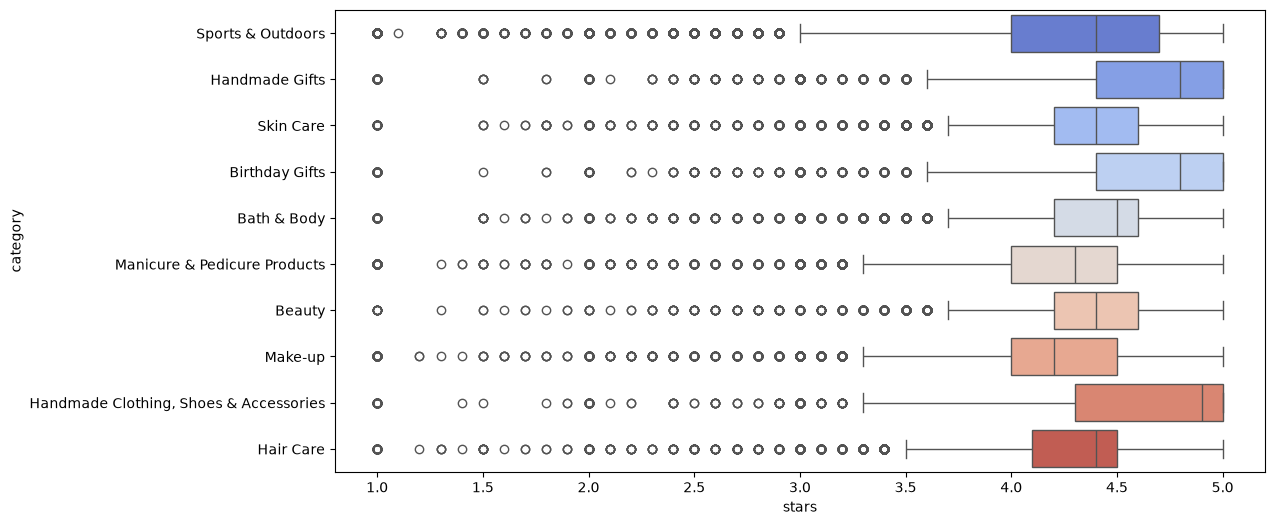

In [ ]:
# 3. Box Plots

boxplot_df = top10_df[top10_df['stars'] > 0]

plt.figure(figsize=(12,6))
sns.boxplot(data=boxplot_df, x='stars', y='category', palette='coolwarm')
plt.show()

In [134]:
median_rating = df_clean.groupby('category')['stars'].median().round(2).sort_values(ascending=False)
print(f"Top 10 categories with the highest median_rating: {median_rating.head(10)}")

Top 10 categories with the highest median_rating: category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64


Part 3: Investigating the Interplay Between Product Prices and Ratings

In [155]:
pearson_coef = df_clean['price'].corr(df['stars'], method='pearson')
spearmann_coef = df_clean['price'].corr(df['stars'], method='spearman')
print(f"The pearson coefficient is: {pearson_coef.round(2)}")
print(f"The spearmann coefficient is: {spearmann_coef.round(2)}")

The pearson coefficient is: -0.08
The spearmann coefficient is: -0.07


The Pearson and Spearman correlations between price and rating are weak at -0.12, -0.13 which suggests that price is not a meaningful predictor of customer rating in this dataset.

<Axes: xlabel='stars', ylabel='price'>

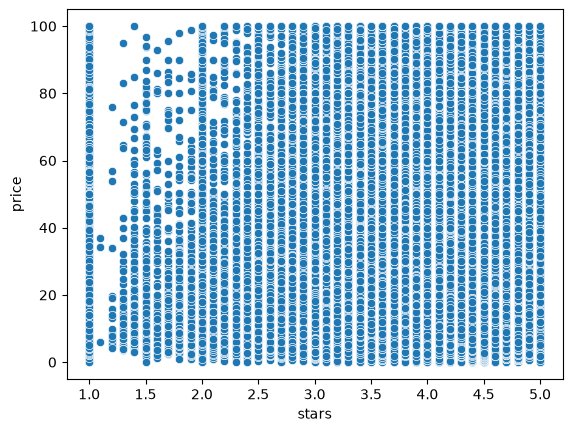

In [156]:
plot_df = df_clean[df_clean['stars']>0]
sns.scatterplot(data=plot_df, x='stars', y='price')


In [152]:
num = df_clean.select_dtypes(include="number")

In [153]:
correlation_matrix = num.corr()

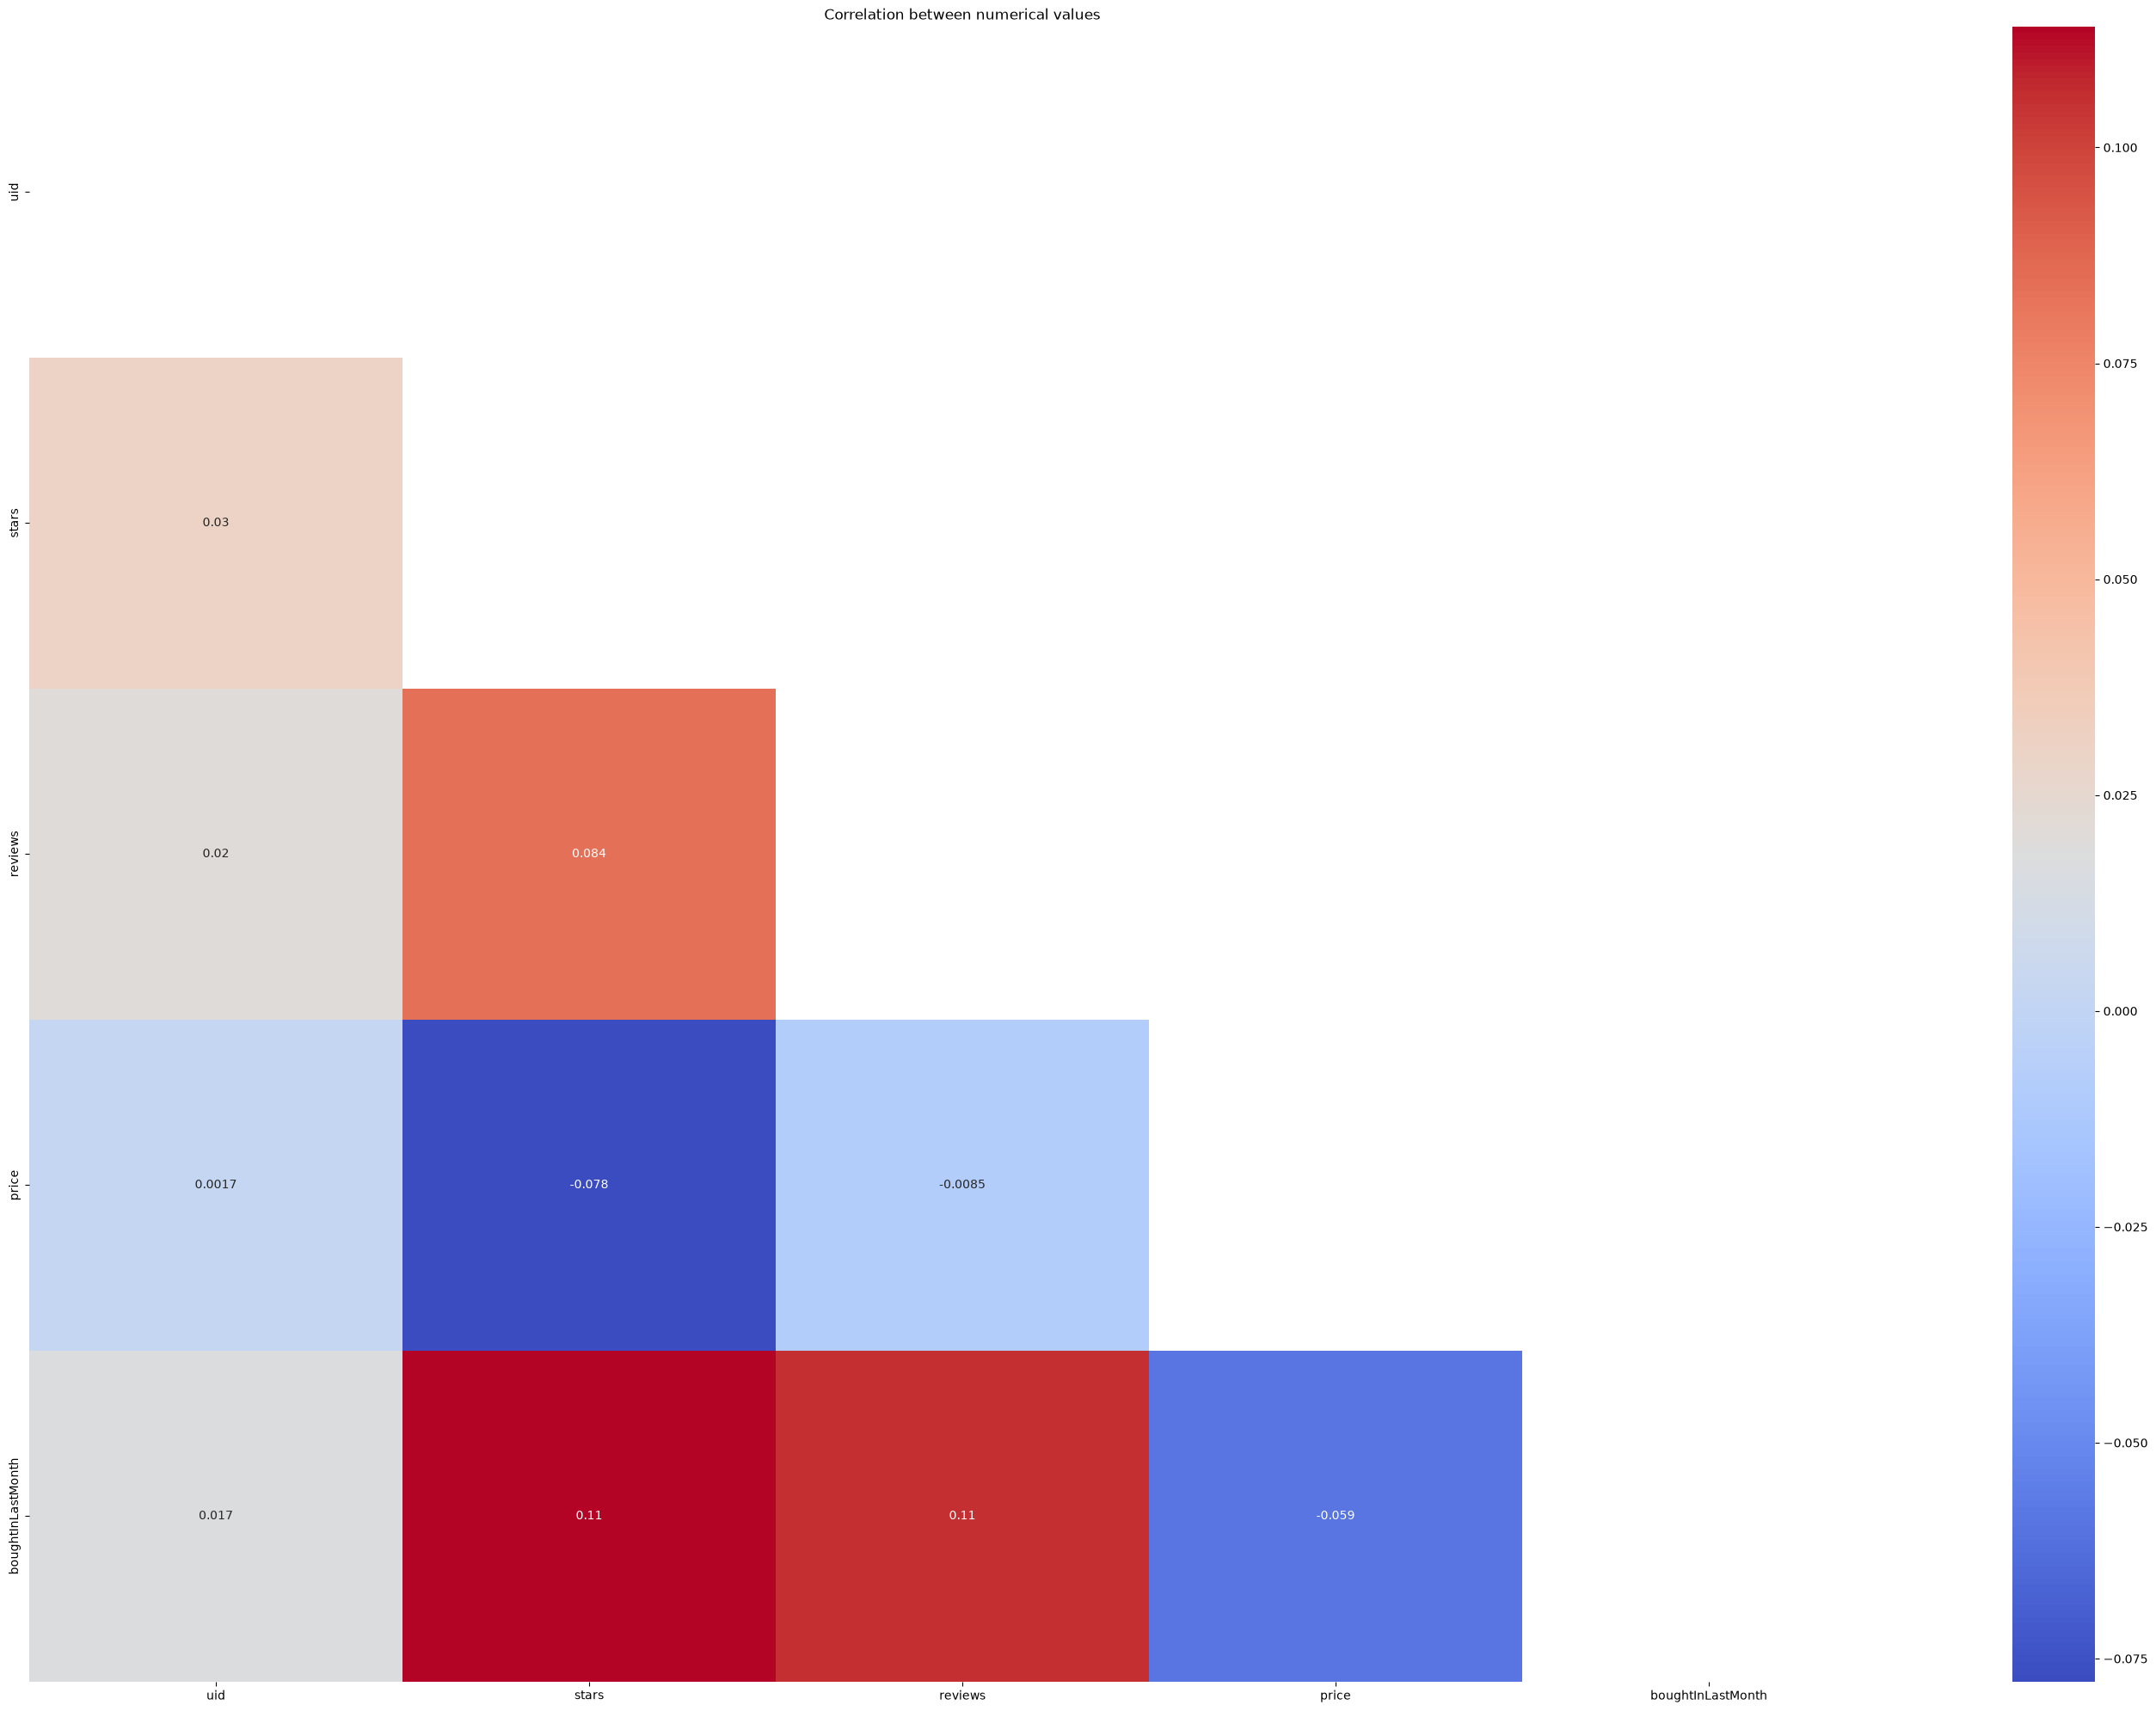

In [154]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(35, 25))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Correlation between numerical values")
plt.show()

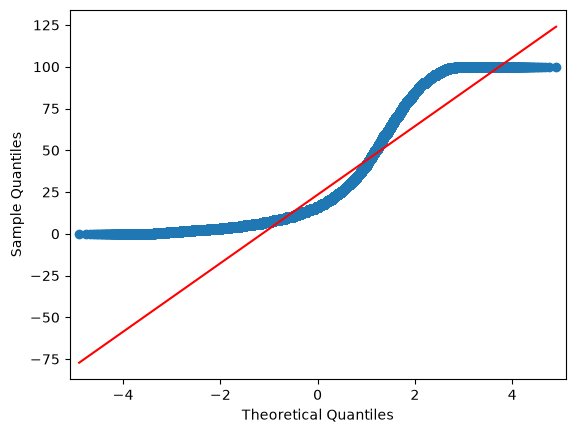

In [158]:
import statsmodels.api as sm

sm.qqplot(df_clean['price'], line= 's')
plt.show()

None of the numeric variables in this dataset (price, stars, reviews, boughtInLastMonth) show strong correlations, as coefficients are below ~0.15 in magnitude. This suggests that price is not a strong predictor of customer ratings or recent purchase volume, and vice versa. Even though still weak, the strongest relationships can be observed between metrics like reviews, stars and recent sales such as boughtInLastMonth, hinting that social proof has a small positive association with purchasing. However, price itself appears to be largely independent of how well-rated or well-reviewed a product is. Additionally, from the QQ plot it's visble that the price distribution deviates substantially from a normal distribution.